# Section 3 — Image Filtering, Thresholding & Edge Detection

### Clean and Analyze Images

In the previous sections, we learned how to:
- read and write images with OpenCV
- understand color spaces
- work with NumPy arrays and image `dtype`
- augment and annotate images
- create masks and use bitwise operations
- draw shapes and text

Now we will learn how to **clean images, separate objects from their background, modify object shapes, and detect boundaries**.

### Learning goals

By the end of this section, you should be able to:

1. Explain why images contain noise.
2. Add and visualize Gaussian and salt-and-pepper noise.
3. Apply smoothing filters and understand their differences.
4. Separate foreground and background using thresholding.
5. Compare binary, inverse, adaptive, and Otsu thresholding.
6. Use erosion, dilation, opening, and closing.
7. Understand image derivatives and gradients.
8. Apply Sobel X/Y, gradient magnitude, Laplacian, and Canny edge detection.

### Main idea

We will follow this pipeline:

**Noise → Filtering → Thresholding → Morphology → Gradients → Edge Detection**

In [1]:
# Basic imports
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)

OpenCV version: 5.0.0
NumPy version: 2.1.3


## 0. Create a clean test image

To make the notebook reproducible, we will create a simple grayscale image containing:
- a rectangle
- a circle
- a smaller bright object
- a smooth background

We can use this same image throughout the lesson so that students can clearly see what each operation changes.

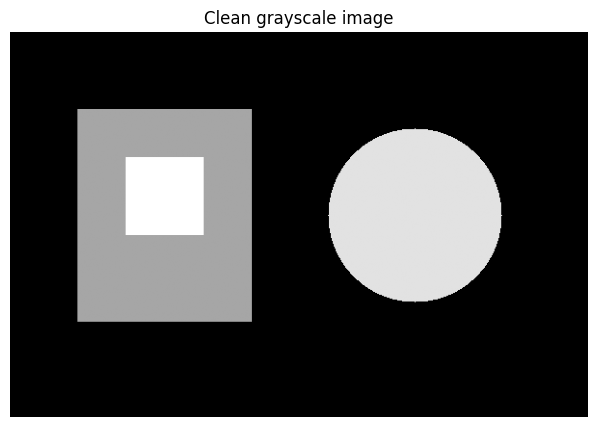

Shape: (400, 600)
dtype: uint8
Intensity range: 40 to 255


In [2]:
# Create a grayscale test image
img = np.zeros((400, 600), dtype=np.uint8)

# Smooth background
img[:] = 40

# Objects
cv2.rectangle(img, (70, 80), (250, 300), 180, -1)
cv2.circle(img, (420, 190), 90, 230, -1)
cv2.rectangle(img, (120, 130), (200, 210), 255, -1)

plt.figure(figsize=(9, 5))
plt.imshow(img, cmap="gray")
plt.title("Clean grayscale image")
plt.axis("off")
plt.show()

print("Shape:", img.shape)
print("dtype:", img.dtype)
print("Intensity range:", img.min(), "to", img.max())

# Lesson 1 — Noise and Image Quality

## What is noise?

**Noise** is unwanted random variation in pixel values.

Real images can contain noise because of:
- low light
- camera sensors
- transmission errors
- compression
- environmental conditions

Noise can make later algorithms less reliable.

For example, an edge detector may interpret a random noisy pixel as an edge.

We will study two common types:

### 1. Gaussian noise
Pixel values are changed using random values drawn from a Gaussian (normal) distribution.

### 2. Salt-and-pepper noise
Some pixels are randomly changed to extreme values:
- `0` → pepper
- `255` → salt

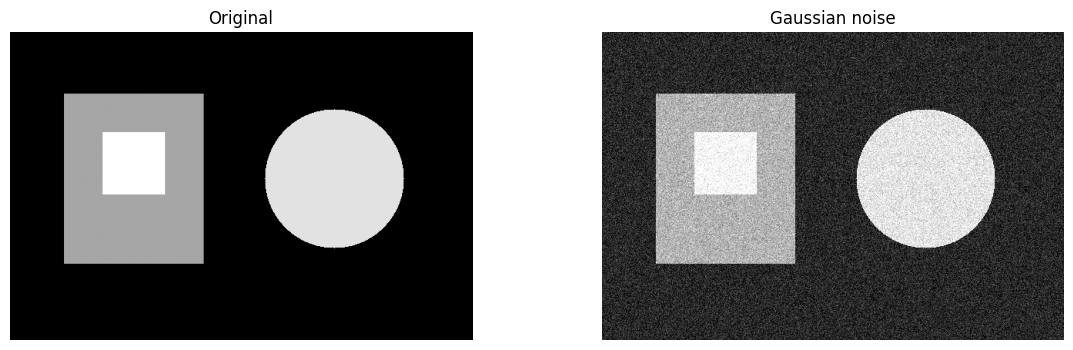

In [3]:
# Add Gaussian noise
def add_gaussian_noise(image, mean=0, sigma=25):
    noise = np.random.normal(mean, sigma, image.shape)
    noisy = image.astype(np.float32) + noise
    return np.clip(noisy, 0, 255).astype(np.uint8)

np.random.seed(42)
gaussian_noisy = add_gaussian_noise(img, sigma=25)

plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gaussian_noisy, cmap="gray")
plt.title("Gaussian noise")
plt.axis("off")

plt.show()

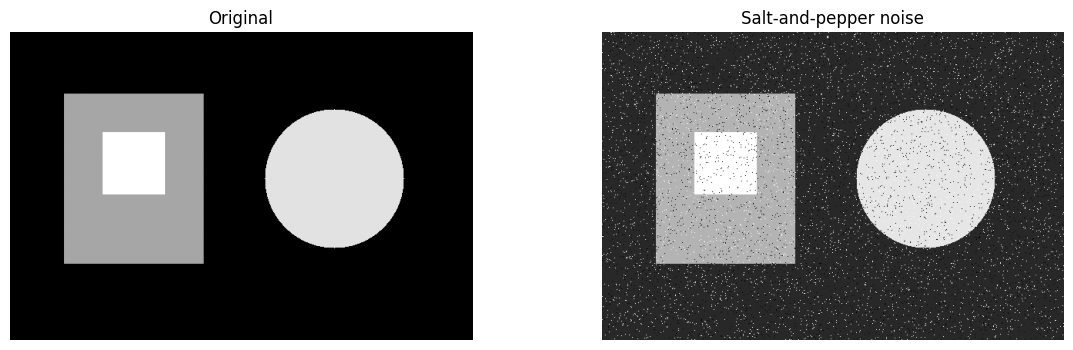

In [4]:
# Add salt-and-pepper noise
def add_salt_pepper_noise(image, amount=0.03):
    noisy = image.copy()
    total_pixels = image.size
    num_pixels = int(amount * total_pixels)

    # Pepper
    rows = np.random.randint(0, image.shape[0], num_pixels)
    cols = np.random.randint(0, image.shape[1], num_pixels)
    noisy[rows, cols] = 0

    # Salt
    rows = np.random.randint(0, image.shape[0], num_pixels)
    cols = np.random.randint(0, image.shape[1], num_pixels)
    noisy[rows, cols] = 255

    return noisy

np.random.seed(42)
sp_noisy = add_salt_pepper_noise(img, amount=0.02)

plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sp_noisy, cmap="gray")
plt.title("Salt-and-pepper noise")
plt.axis("off")

plt.show()

### Observation

Notice that the two noise types look different.

- **Gaussian noise** spreads small intensity changes across the image.
- **Salt-and-pepper noise** creates isolated very dark and very bright pixels.

This difference matters because different filters handle different noise types better.

# Lesson 2 — Image Filtering

Filtering changes a pixel using information from its neighborhood.

A simple way to think about filtering is:

> **The new pixel value depends on nearby pixels.**

We will compare:

- Average blur
- Gaussian blur
- Median blur
- Bilateral filtering

The main filters required for this section are **Gaussian blur** and **median blur**.

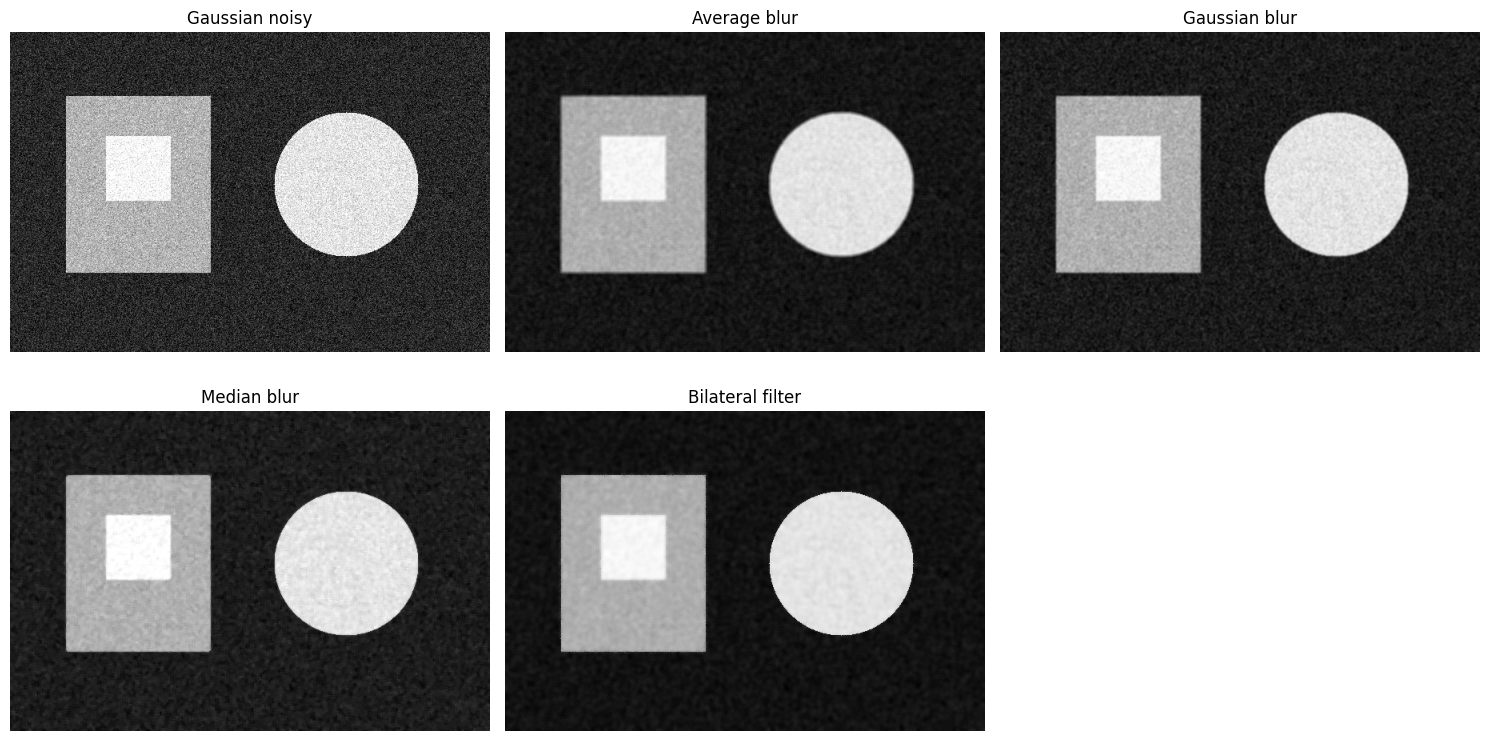

In [5]:
# Apply different filters to Gaussian noise
average = cv2.blur(gaussian_noisy, (5, 5))
gaussian = cv2.GaussianBlur(gaussian_noisy, (5, 5), 0)
median = cv2.medianBlur(gaussian_noisy, 5)
bilateral = cv2.bilateralFilter(gaussian_noisy, 9, 75, 75)

titles = [
    "Gaussian noisy",
    "Average blur",
    "Gaussian blur",
    "Median blur",
    "Bilateral filter"
]
images = [
    gaussian_noisy,
    average,
    gaussian,
    median,
    bilateral
]

plt.figure(figsize=(15, 8))
for i, (title, image) in enumerate(zip(titles, images), 1):
    plt.subplot(2, 3, i)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

## Gaussian Blur

`cv2.GaussianBlur()` gives more importance to pixels near the center of the neighborhood.

```python
blur = cv2.GaussianBlur(image, (5, 5), 0)
```

### Important idea

A larger kernel usually means stronger smoothing.

For example:

- `(3, 3)` → lighter smoothing
- `(5, 5)` → stronger smoothing
- `(9, 9)` → even stronger smoothing

The kernel size should normally be positive and odd.

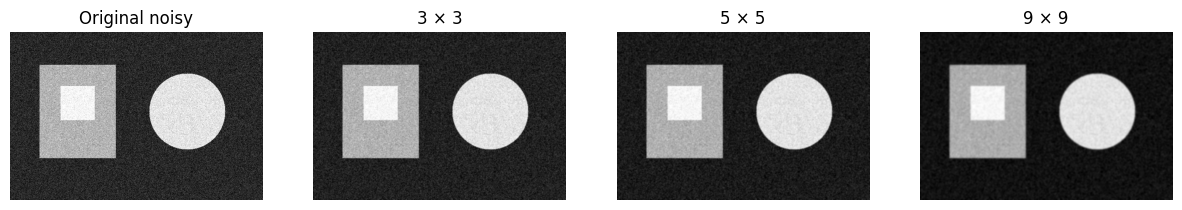

In [6]:
# Compare Gaussian kernel sizes
blur_3 = cv2.GaussianBlur(gaussian_noisy, (3, 3), 0)
blur_5 = cv2.GaussianBlur(gaussian_noisy, (5, 5), 0)
blur_9 = cv2.GaussianBlur(gaussian_noisy, (9, 9), 0)

plt.figure(figsize=(15, 4))

for i, (title, image) in enumerate([
    ("Original noisy", gaussian_noisy),
    ("3 × 3", blur_3),
    ("5 × 5", blur_5),
    ("9 × 9", blur_9)
], 1):
    plt.subplot(1, 4, i)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.show()

## Median Blur

`cv2.medianBlur()` replaces a pixel with the **median** of its neighborhood.

It is especially useful for **salt-and-pepper noise** because extreme values are less likely to survive the median operation.

Example:

Neighborhood:

`[20, 21, 22, 23, 255]`

Median:

`22`

The extreme `255` does not dominate the result.

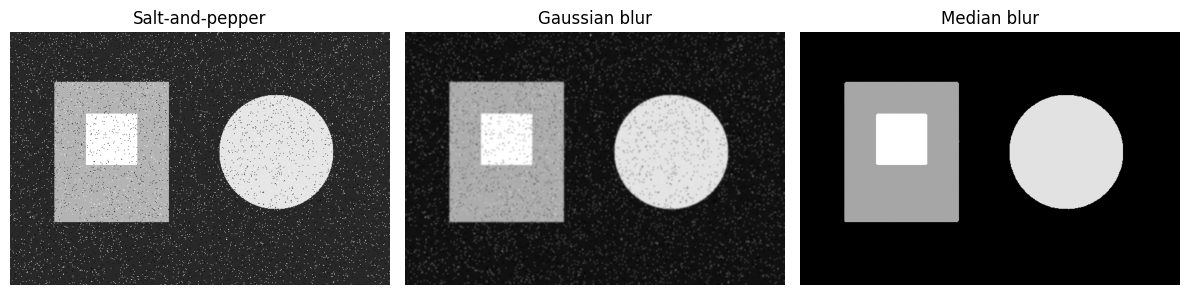

In [23]:
median_sp = cv2.medianBlur(sp_noisy, 5)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(sp_noisy, cmap="gray")
plt.title("Salt-and-pepper")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.GaussianBlur(sp_noisy, (5, 5), 0), cmap="gray")
plt.title("Gaussian blur")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(median_sp, cmap="gray")
plt.title("Median blur")
plt.axis("off")

plt.tight_layout()
plt.show()

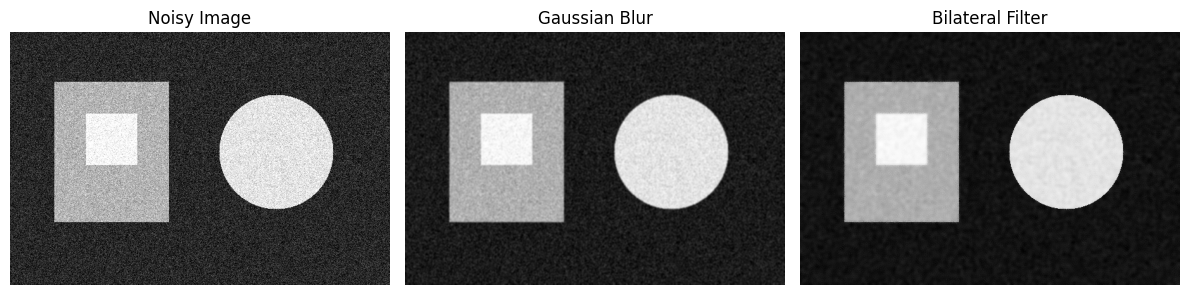

In [21]:
# Bilateral Filtering
# Reduces noise while trying to preserve important edges

bilateral = cv2.bilateralFilter(
    gaussian_noisy,
    d=9,
    sigmaColor=75,
    sigmaSpace=75
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(gaussian_noisy, cmap="gray")
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.GaussianBlur(gaussian_noisy, (5, 5), 0), cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(bilateral, cmap="gray")
plt.title("Bilateral Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

### Filtering comparison

| Filter | Main idea | Good use |
|---|---|---|
| Average | Mean of neighborhood | Simple smoothing |
| Gaussian | Weighted smoothing | General noise reduction |
| Median | Median of neighborhood | Salt-and-pepper noise |
| Bilateral | Smooths while preserving edges | Noise reduction with edge preservation |

### Important trade-off

Filtering reduces noise, but **too much filtering can remove useful details and edges**.

So filtering is usually a balance:

**less noise ↔ preserve important structures**

# Lesson 3 — Image Thresholding

Thresholding converts an image into regions based on pixel intensity.

The basic idea is:

> If a pixel is brighter/darker than a chosen threshold, classify it differently.

For a simple binary threshold:

- intensity > threshold → `255`
- intensity ≤ threshold → `0`

This is one of the simplest forms of **image segmentation**.

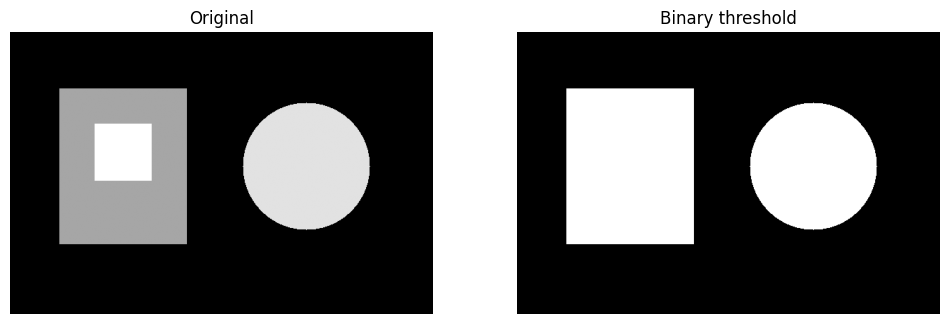

In [8]:
# Create a simple threshold
threshold_value = 120

_, binary = cv2.threshold(img, threshold_value, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binary threshold")
plt.axis("off")

plt.show()

## Binary vs Inverse Thresholding

OpenCV provides:

- `cv2.THRESH_BINARY`
- `cv2.THRESH_BINARY_INV`

They perform opposite classifications.

### Binary

Bright pixels become white.

### Binary inverse

Bright pixels become black and darker pixels become white.

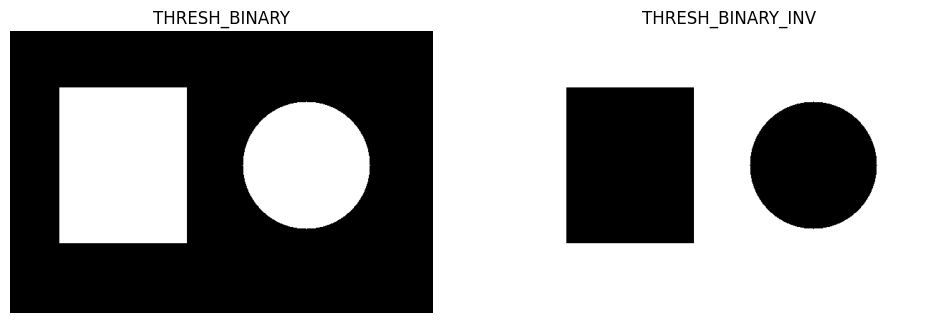

In [9]:
_, binary = cv2.threshold(img, 120, 255, cv2.THRESH_BINARY)
_, binary_inv = cv2.threshold(img, 120, 255, cv2.THRESH_BINARY_INV)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(binary, cmap="gray")
plt.title("THRESH_BINARY")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_inv, cmap="gray")
plt.title("THRESH_BINARY_INV")
plt.axis("off")

plt.show()

## Adaptive Thresholding

A single global threshold does not work well when lighting changes across an image.

Adaptive thresholding calculates a threshold from a **local neighborhood**.

OpenCV examples:

```python
cv2.ADAPTIVE_THRESH_MEAN_C
cv2.ADAPTIVE_THRESH_GAUSSIAN_C
```

This is useful for images such as documents photographed under uneven lighting.

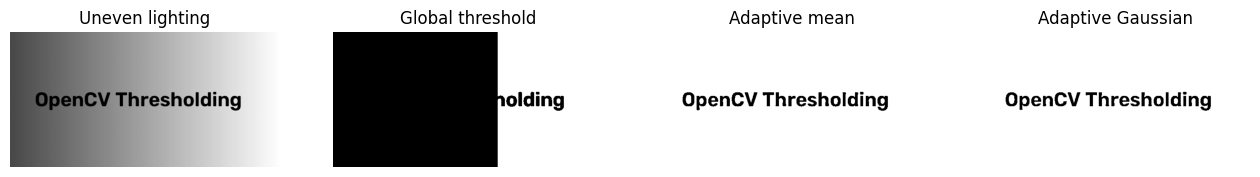

In [10]:
# Create a synthetic uneven-light document-like image
h, w = 300, 600
x = np.linspace(0, 1, w)
gradient = np.tile((60 + 100 * x).astype(np.uint8), (h, 1))

document = gradient.copy()

cv2.putText(
    document, "OpenCV Thresholding",
    (55, 165),
    cv2.FONT_HERSHEY_SIMPLEX,
    1.5, 20, 3, cv2.LINE_AA
)

global_binary = cv2.threshold(document, 120, 255, cv2.THRESH_BINARY)[1]

adaptive_mean = cv2.adaptiveThreshold(
    document, 255,
    cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY,
    21, 5
)

adaptive_gaussian = cv2.adaptiveThreshold(
    document, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    21, 5
)

plt.figure(figsize=(16, 4))

for i, (title, image) in enumerate([
    ("Uneven lighting", document),
    ("Global threshold", global_binary),
    ("Adaptive mean", adaptive_mean),
    ("Adaptive Gaussian", adaptive_gaussian)
], 1):
    plt.subplot(1, 4, i)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.show()

## Otsu Thresholding

Sometimes we do not know the best threshold value.

Otsu's method automatically chooses a threshold by analyzing the intensity distribution.

```python
threshold, result = cv2.threshold(
    image, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
```

The returned `threshold` is the threshold value selected by Otsu's method.

Otsu selected threshold: 40.0


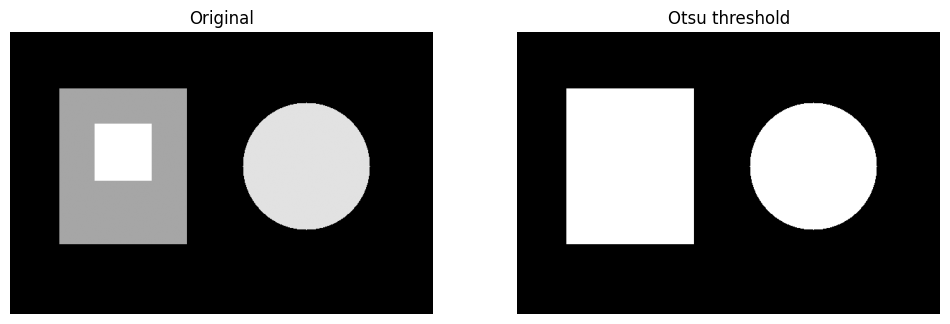

In [11]:
otsu_threshold, otsu = cv2.threshold(
    img, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Otsu selected threshold:", otsu_threshold)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(otsu, cmap="gray")
plt.title("Otsu threshold")
plt.axis("off")

plt.show()

### Thresholding decision guide

| Method | When to use |
|---|---|
| Binary | You know a suitable global threshold |
| Binary inverse | You need the opposite foreground/background |
| Adaptive | Lighting changes across the image |
| Otsu | You want an automatic global threshold and the histogram is reasonably bimodal |

### Key question

Before choosing a thresholding method, ask:

**Is one threshold suitable for the whole image?**

If yes → global methods may work.

If no → adaptive thresholding may be better.

# Lesson 4 — Morphological Operations

Morphology works mainly with **binary images** and a small shape called a **kernel** or **structuring element**.

The four core operations are:

1. Erosion
2. Dilation
3. Opening
4. Closing

These operations change the shape and connectivity of foreground regions.

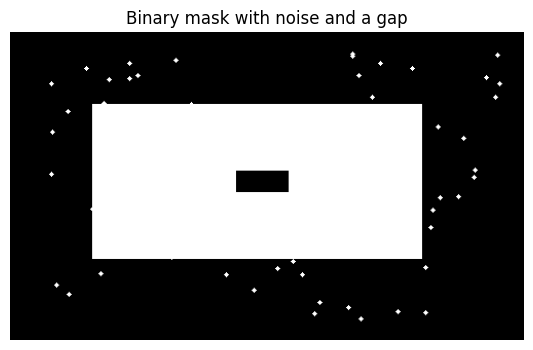

In [7]:
# Create a binary image with small noise and a small gap
mask = np.zeros((300, 500), dtype=np.uint8)

cv2.rectangle(mask, (80, 70), (400, 220), 255, -1)

# Add small foreground noise
np.random.seed(1)
for _ in range(80):
    x = np.random.randint(20, 480)
    y = np.random.randint(20, 280)
    cv2.circle(mask, (x, y), 2, 255, -1)

# Add a small black gap inside the object
cv2.rectangle(mask, (220, 135), (270, 155), 0, -1)

plt.figure(figsize=(8, 4))
plt.imshow(mask, cmap="gray")
plt.title("Binary mask with noise and a gap")
plt.axis("off")
plt.show()

## Kernel

A kernel defines the neighborhood used by a morphological operation.

```python
kernel = np.ones((5, 5), np.uint8)
```

You can change its size to change the strength of the operation.

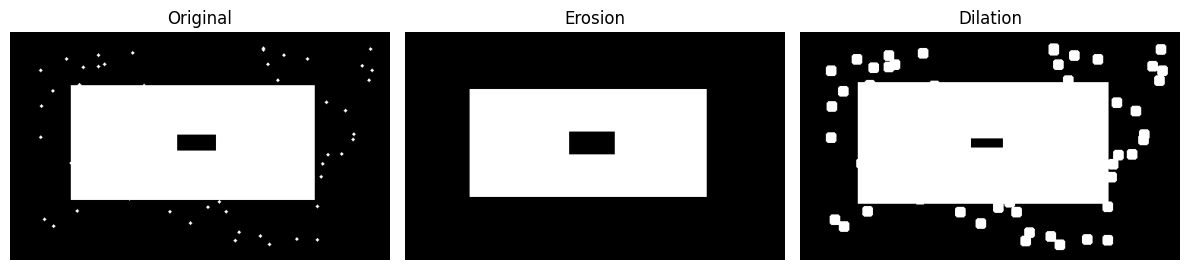

In [10]:
kernel = np.ones((10, 10), np.uint8)

erosion = cv2.erode(mask, kernel, iterations=1)
dilation = cv2.dilate(mask, kernel, iterations=1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(mask, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(erosion, cmap="gray")
plt.title("Erosion")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(dilation, cmap="gray")
plt.title("Dilation")
plt.axis("off")

plt.tight_layout()
plt.show()

## Erosion

Erosion tends to **shrink white foreground objects**.

Useful for:
- removing small foreground noise
- separating objects that are very close
- shrinking boundaries

## Dilation

Dilation tends to **expand white foreground objects**.

Useful for:
- filling small gaps
- connecting nearby regions
- expanding boundaries

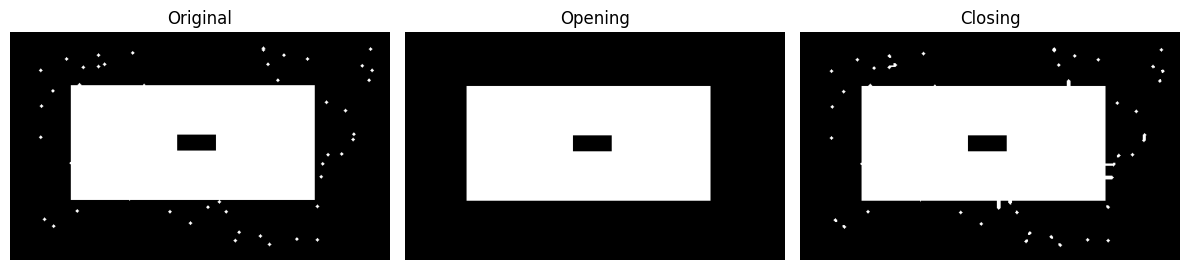

In [11]:
opening = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(mask, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(opening, cmap="gray")
plt.title("Opening")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(closing, cmap="gray")
plt.title("Closing")
plt.axis("off")

plt.tight_layout()
plt.show()

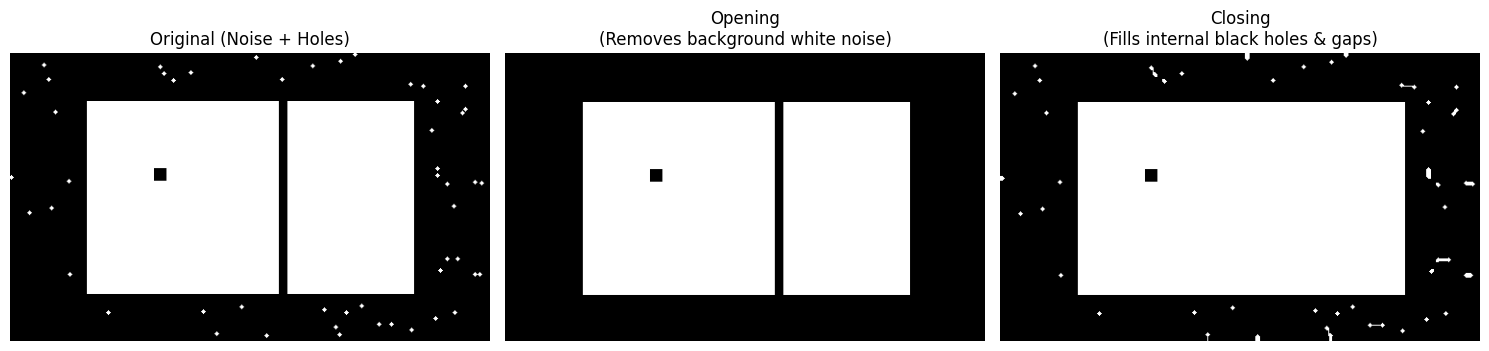

In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a black background
mask = np.zeros((300, 500), dtype=np.uint8)

# 2. Draw a large white rectangle
cv2.rectangle(mask, (80, 50), (420, 250), 255, -1)

# --- ADD NOISE FOR OPENING ---
# Add tiny white spots in the background (salt noise)
np.random.seed(42)
for _ in range(120):
    x = np.random.randint(0, 500)
    y = np.random.randint(0, 300)
    # Ensure noise is in the background area
    if x < 70 or x > 430 or y < 40 or y > 260:
        cv2.circle(mask, (x, y), 2, 255, -1)

# --- ADD HOLES/GAPS FOR CLOSING ---
# Add a small black hole inside the rectangle (12x12 pixels)
cv2.rectangle(mask, (150, 120), (162, 132), 0, -1)

# Add a narrow black slice through the rectangle (gap)
cv2.rectangle(mask, (280, 50), (288, 250), 0, -1)


# 3. Define a Structuring Element (Kernel)
# Kernel size (15x15) is larger than the 12px hole and 8px gap
kernel = np.ones((10, 10), np.uint8)

# 4. Apply Opening and Closing
opening = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

# 5. Visualize the comparison
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(mask, cmap="gray")
plt.title("Original (Noise + Holes)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(opening, cmap="gray")
plt.title("Opening\n(Removes background white noise)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(closing, cmap="gray")
plt.title("Closing\n(Fills internal black holes & gaps)")
plt.axis("off")

plt.tight_layout()
plt.show()

## Opening and Closing

### Opening

**Opening = erosion → dilation**
Opening: Wipes away all the isolated white dots in the background, but leaves the inner black hole and gap intact.

It is useful for removing small foreground objects/noise.

### Closing

**Closing = dilation → erosion**

Closing: Completely seals up the 12px black hole and bridges the 8px split line, but keeps the white noise dots in the background.
It is useful for filling small holes and closing small gaps.

A useful memory trick:

- **Opening cleans small white objects** :
Opening removes isolated white objects (background noise, specks) and detaches weakly connected regions.
- **Closing closes small black gaps/holes** :
Closing fills in dark gaps and holes inside or between white objects.

The result depends on the kernel size and shape.

# Lesson 5 — Derivatives and Edge Detection

An edge is usually a location where image intensity changes quickly.

For example:

**dark → bright**

creates a strong intensity change.

We can detect these changes using image derivatives.

The main tools are:

- Sobel X
- Sobel Y
- Gradient magnitude
- Laplacian
- Canny

## Image gradients

Think of an image as a 2D intensity surface.

- **Sobel X** measures intensity changes mainly from left to right.
- **Sobel Y** measures intensity changes mainly from top to bottom.

A strong derivative means that intensity changes quickly in that direction.

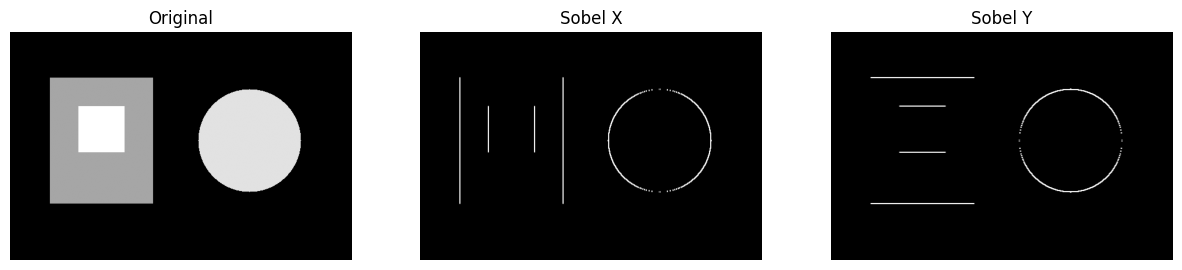

In [15]:
# Use a clean image with clear boundaries
gray = img

sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

# Convert to displayable absolute values
sobel_x_abs = cv2.convertScaleAbs(sobel_x)
sobel_y_abs = cv2.convertScaleAbs(sobel_y)

plt.figure(figsize=(15, 4))

for i, (title, image) in enumerate([
    ("Original", gray),
    ("Sobel X", sobel_x_abs),
    ("Sobel Y", sobel_y_abs)
], 1):
    plt.subplot(1, 3, i)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.show()

### Why are Sobel X and Sobel Y different?

If an edge is mainly **vertical**, intensity changes as we move horizontally.

So the **X derivative** responds strongly.

If an edge is mainly **horizontal**, intensity changes as we move vertically.

So the **Y derivative** responds strongly.

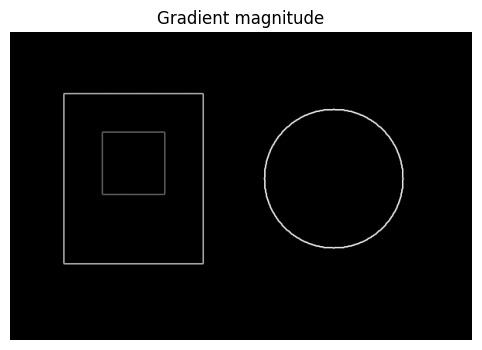

In [16]:
# Gradient magnitude
magnitude = cv2.magnitude(
    sobel_x.astype(np.float32),
    sobel_y.astype(np.float32)
)

magnitude_display = cv2.normalize(
    magnitude, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

plt.figure(figsize=(8, 4))
plt.imshow(magnitude_display, cmap="gray")
plt.title("Gradient magnitude")
plt.axis("off")
plt.show()

## Gradient magnitude

The gradient magnitude combines the X and Y changes.

Conceptually:

**strong X change + strong Y change → strong overall gradient**

This helps us detect edges regardless of their direction.

## Laplacian

The Laplacian uses the second derivative.

It responds strongly to rapid changes in intensity and can highlight edges in multiple directions.

```python
laplacian = cv2.Laplacian(image, cv2.CV_64F)
```

Because derivative operations can also react strongly to noise, smoothing is often useful before edge detection.

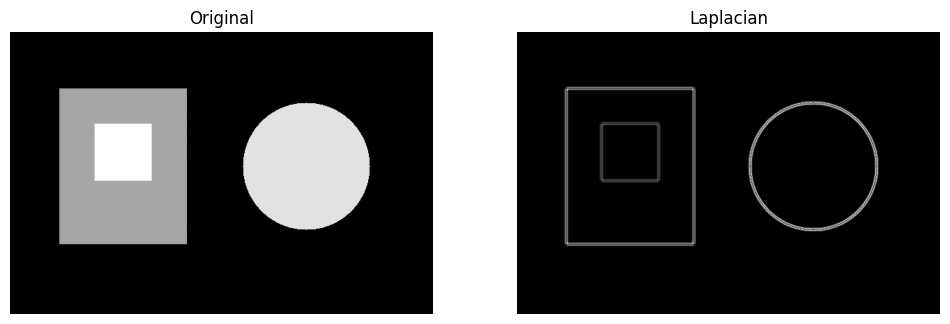

In [17]:
blur_for_edges = cv2.GaussianBlur(gray, (5, 5), 0)

laplacian = cv2.Laplacian(
    blur_for_edges,
    cv2.CV_64F
)

laplacian_abs = cv2.convertScaleAbs(laplacian)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(laplacian_abs, cmap="gray")
plt.title("Laplacian")
plt.axis("off")

plt.show()

# Canny Edge Detection

Canny is a more complete edge-detection pipeline.

A simplified view is:

1. Smooth the image.
2. Calculate gradients.
3. Keep thin/local maximum edges.
4. Use two thresholds.
5. Connect strong edges with relevant weak edges.

OpenCV:

```python
edges = cv2.Canny(image, threshold1, threshold2)
```

The two thresholds are important:

- lower threshold
- upper threshold

Changing them changes how many edges are detected.

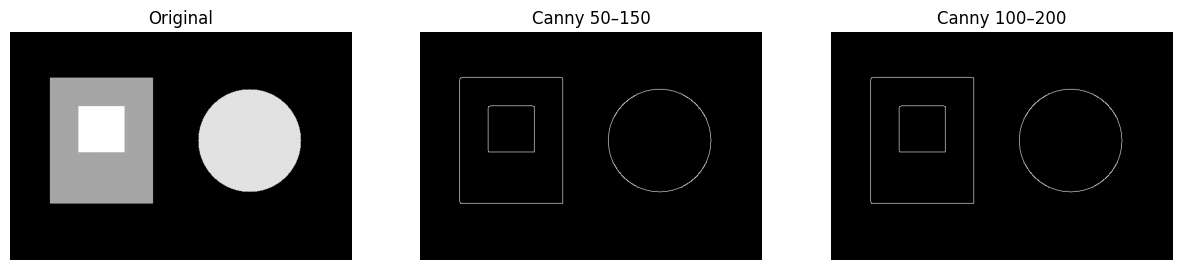

In [18]:
# Canny edge detection
canny_50_150 = cv2.Canny(blur_for_edges, 50, 150)
canny_100_200 = cv2.Canny(blur_for_edges, 100, 200)

plt.figure(figsize=(15, 4))

for i, (title, image) in enumerate([
    ("Original", gray),
    ("Canny 50–150", canny_50_150),
    ("Canny 100–200", canny_100_200)
], 1):
    plt.subplot(1, 3, i)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.show()

## Why blur before Canny?

Noise creates small intensity changes.

Canny is designed to find intensity changes, so noisy pixels can create unwanted edges.

A common pipeline is:

**Image → Gaussian Blur → Canny**

This is a good example of how the topics in this section work together.

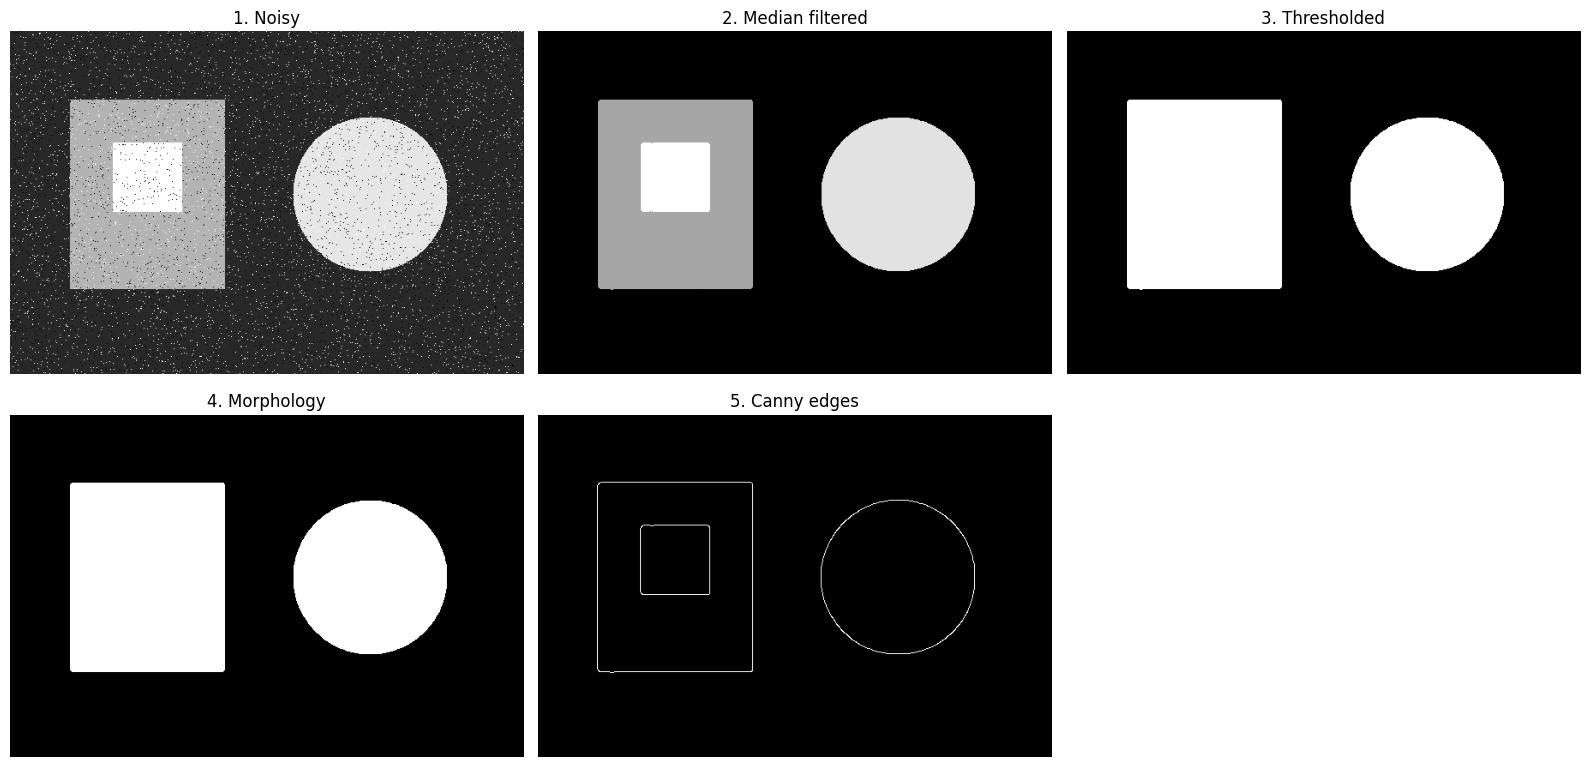

In [19]:
# Complete practical pipeline:
# noisy image -> smoothing -> threshold -> morphology -> edges

np.random.seed(7)
noisy = add_salt_pepper_noise(img, amount=0.02)

# 1. Remove salt-and-pepper noise
cleaned = cv2.medianBlur(noisy, 5)

# 2. Segment foreground
_, segmented = cv2.threshold(
    cleaned, 100, 255, cv2.THRESH_BINARY
)

# 3. Clean the segmentation
kernel = np.ones((5, 5), np.uint8)
segmented_clean = cv2.morphologyEx(
    segmented, cv2.MORPH_OPEN, kernel
)
segmented_clean = cv2.morphologyEx(
    segmented_clean, cv2.MORPH_CLOSE, kernel
)

# 4. Detect edges
edges = cv2.Canny(cleaned, 50, 150)

plt.figure(figsize=(16, 8))

for i, (title, image) in enumerate([
    ("1. Noisy", noisy),
    ("2. Median filtered", cleaned),
    ("3. Thresholded", segmented),
    ("4. Morphology", segmented_clean),
    ("5. Canny edges", edges)
], 1):
    plt.subplot(2, 3, i)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Quick Comparison

| Task | OpenCV function |
|---|---|
| Average blur | `cv2.blur()` |
| Gaussian smoothing | `cv2.GaussianBlur()` |
| Median smoothing | `cv2.medianBlur()` |
| Bilateral filtering | `cv2.bilateralFilter()` |
| Binary threshold | `cv2.threshold()` |
| Adaptive threshold | `cv2.adaptiveThreshold()` |
| Erosion | `cv2.erode()` |
| Dilation | `cv2.dilate()` |
| Opening | `cv2.morphologyEx(..., cv2.MORPH_OPEN)` |
| Closing | `cv2.morphologyEx(..., cv2.MORPH_CLOSE)` |
| Sobel X/Y | `cv2.Sobel()` |
| Laplacian | `cv2.Laplacian()` |
| Canny | `cv2.Canny()` |

# Mini Practice Tasks

Try these without looking at the previous cells.

### Task 1 — Noise
1. Change Gaussian noise `sigma` from `25` to `50`.
2. Change salt-and-pepper noise from `0.02` to `0.08`.
3. Compare which image becomes harder to recognize.

### Task 2 — Filtering
Apply:
- Gaussian blur with `(3,3)`
- Gaussian blur with `(11,11)`
- median blur with `3`
- median blur with `9`

**Question:** Which filter preserves the object boundaries better?

### Task 3 — Thresholding
Try threshold values:
- `60`
- `120`
- `200`

Then compare with Otsu.

**Question:** When does a manually selected threshold fail?

### Task 4 — Morphology
Change the kernel:
```python
np.ones((3,3), np.uint8)
np.ones((7,7), np.uint8)
np.ones((11,11), np.uint8)
```

Compare opening and closing.

**Question:** What happens when the kernel becomes too large?

### Task 5 — Edge Detection
Try Canny with:
- `(30, 100)`
- `(50, 150)`
- `(100, 200)`

**Question:** Which setting detects more edges? Which produces more unwanted edges?

### Task 6 — Build your own pipeline
Create this pipeline for an image of your choice:

**Read → Grayscale → Add/observe noise → Filter → Threshold → Morphology → Canny**

Explain in comments why you selected each operation.

# Final Challenge — Document Cleanup

Imagine you have a photographed document containing:

- uneven lighting
- small noise
- dark text
- small gaps in letters

Build a pipeline that tries to produce a clean binary document.

Suggested stages:

1. Convert to grayscale.
2. Apply Gaussian or median filtering.
3. Use adaptive thresholding.
4. Apply morphology.
5. Display the original and final result.

### Extension

Try the same image with:
- global thresholding
- Otsu
- adaptive thresholding

Then explain which method works best and **why**.

In [20]:
# Student challenge template
# Replace `document_image` with your own image.

# document_image = cv2.imread("your_image.jpg")
# gray_doc = cv2.cvtColor(document_image, cv2.COLOR_BGR2GRAY)

# Step 1: filtering

# Step 2: adaptive threshold


# Step 3: morphology


# plt.figure(figsize=(12, 4))
# plt.subplot(1, 2, 1)
# plt.imshow(gray_doc, cmap="gray")
# plt.title("Original")
# plt.axis("off")

# plt.subplot(1, 2, 2)
# plt.imshow(clean_doc, cmap="gray")
# plt.title("Cleaned document")
# plt.axis("off")

# plt.show()

# Solutions — Amr

The cells below rebuild the section's test image and noise functions, so they run on their own (Colab: *Runtime → Run all*, no upload needed).
Task 6 uses OpenCV's sample photo `fruits.jpg`, downloaded from the OpenCV repository.

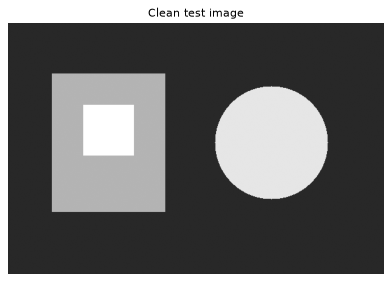

In [1]:
import os
import urllib.request

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Same clean test image as the section
img = np.full((400, 600), 40, dtype=np.uint8)
cv2.rectangle(img, (70, 80), (250, 300), 180, -1)
cv2.circle(img, (420, 190), 90, 230, -1)
cv2.rectangle(img, (120, 130), (200, 210), 255, -1)


def add_gaussian_noise(image, mean=0, sigma=25):
    noise = np.random.normal(mean, sigma, image.shape)
    noisy = image.astype(np.float32) + noise
    return np.clip(noisy, 0, 255).astype(np.uint8)


def add_salt_pepper_noise(image, amount=0.03):
    noisy = image.copy()
    n = int(amount * image.size)
    rows = np.random.randint(0, image.shape[0], n)
    cols = np.random.randint(0, image.shape[1], n)
    noisy[rows, cols] = 0
    rows = np.random.randint(0, image.shape[0], n)
    cols = np.random.randint(0, image.shape[1], n)
    noisy[rows, cols] = 255
    return noisy


def show(images, titles, cols=None, size=3.4):
    cols = cols or len(images)
    rows = int(np.ceil(len(images) / cols))
    plt.figure(figsize=(size * cols, size * 0.75 * rows), dpi=80)
    for i, (im, t) in enumerate(zip(images, titles), 1):
        plt.subplot(rows, cols, i)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(t, fontsize=10)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


show([img], ["Clean test image"], size=5)

### Task 1 — Noise (Solution)

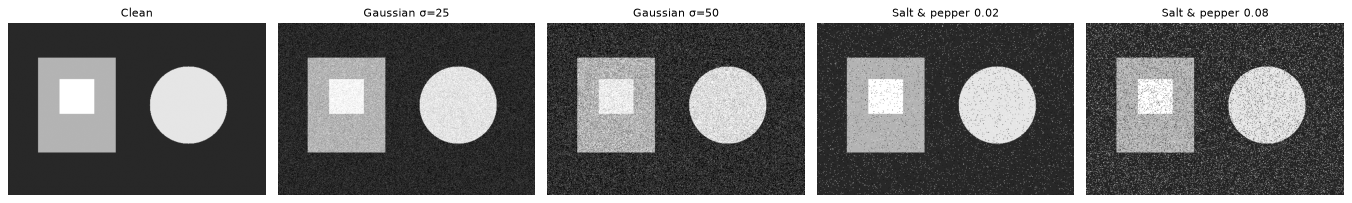

image                  PSNR (dB)   changed pixels
Gaussian sigma=25          20.67            66.5%
Gaussian sigma=50          15.69            82.2%
Salt&pepper 0.02           18.37             3.9%
Salt&pepper 0.08           12.64            14.6%


In [2]:
np.random.seed(42)
g25 = add_gaussian_noise(img, sigma=25)
g50 = add_gaussian_noise(img, sigma=50)

np.random.seed(42)
sp02 = add_salt_pepper_noise(img, amount=0.02)
sp08 = add_salt_pepper_noise(img, amount=0.08)

show([img, g25, g50, sp02, sp08],
     ["Clean", "Gaussian σ=25", "Gaussian σ=50", "Salt & pepper 0.02", "Salt & pepper 0.08"])

# PSNR: higher = closer to the clean image
print(f"{'image':<22}{'PSNR (dB)':>10}{'changed pixels':>17}")
for name, im in [("Gaussian sigma=25", g25), ("Gaussian sigma=50", g50),
                 ("Salt&pepper 0.02", sp02), ("Salt&pepper 0.08", sp08)]:
    changed = np.mean(np.abs(im.astype(int) - img) > 10) * 100
    print(f"{name:<22}{cv2.PSNR(img, im):>10.2f}{changed:>16.1f}%")

**Which image is harder to recognize?**
- Doubling the Gaussian sigma (25 → 50) drops the PSNR from 20.7 to 15.7 dB. Almost every pixel changes, so the whole image becomes grainy and the gray rectangle starts to blend into the background, but the shapes are still visible.
- Raising salt & pepper from 0.02 to 0.08 drops the PSNR from 18.4 to **12.6 dB**, the lowest of the four. About 15% of the pixels become pure black or white, so the dots cover the objects, and the small bright square is the hardest part to see.
- **Salt & pepper 0.08 is the hardest to recognize.** Gaussian σ=50 changes more pixels, but each change is smaller.

### Task 2 — Filtering (Solution)

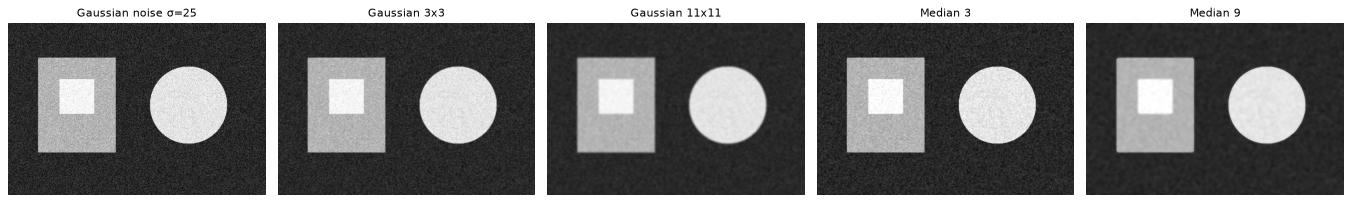

Gaussian noise σ=25 -> PSNR after filtering: Gaussian 3x3: 28.0 dB, Gaussian 11x11: 28.7 dB, Median 3: 27.8 dB, Median 9: 32.6 dB


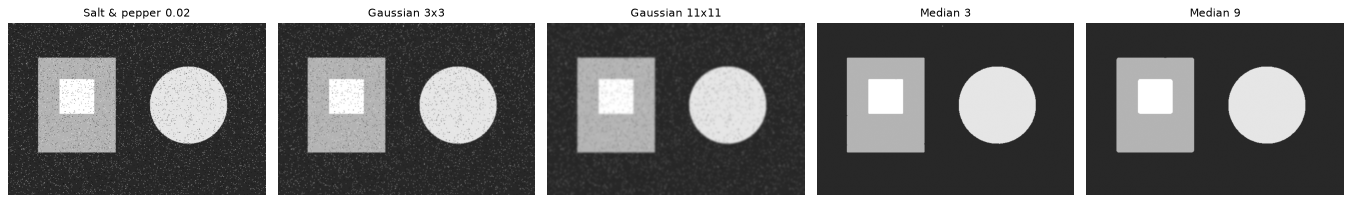

Salt & pepper 0.02 -> PSNR after filtering: Gaussian 3x3: 25.9 dB, Gaussian 11x11: 27.9 dB, Median 3: 41.3 dB, Median 9: 38.4 dB


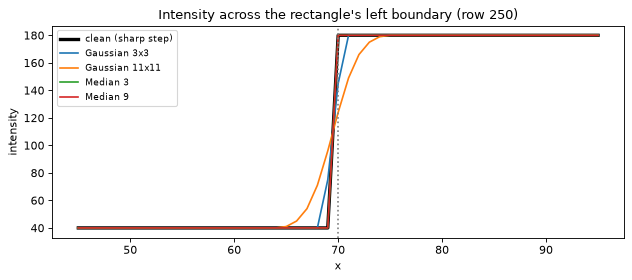

Edge width (10%-90%) on the clean image: Gaussian 3x3: 2 px, Gaussian 11x11: 4 px, Median 3: 0 px, Median 9: 0 px


In [3]:
def apply_filters(noisy):
    return {
        "Gaussian 3x3": cv2.GaussianBlur(noisy, (3, 3), 0),
        "Gaussian 11x11": cv2.GaussianBlur(noisy, (11, 11), 0),
        "Median 3": cv2.medianBlur(noisy, 3),
        "Median 9": cv2.medianBlur(noisy, 9),
    }

for noisy, label in [(g25, "Gaussian noise σ=25"), (sp02, "Salt & pepper 0.02")]:
    results = apply_filters(noisy)
    show([noisy] + list(results.values()), [label] + list(results.keys()), cols=5)
    print(label, "-> PSNR after filtering:",
          ", ".join(f"{k}: {cv2.PSNR(img, v):.1f} dB" for k, v in results.items()))

# Boundary sharpness: filter the CLEAN image and look at a row crossing the left edge of the rectangle (x = 70)
row = 250
xs = np.arange(45, 96)
plt.figure(figsize=(8, 3.6), dpi=80)
plt.plot(xs, img[row, xs], "k-", lw=3, label="clean (sharp step)")
for name, f in apply_filters(img).items():
    plt.plot(xs, f[row, xs], label=name)
plt.axvline(70, color="gray", ls=":")
plt.title(f"Intensity across the rectangle's left boundary (row {row})")
plt.xlabel("x")
plt.ylabel("intensity")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

def edge_width(profile):
    # pixels needed to go from 10% to 90% of the step (40 -> 180)
    lo, hi = 40 + 0.1 * 140, 40 + 0.9 * 140
    return int(np.sum((profile > lo) & (profile < hi)))

print("Edge width (10%-90%) on the clean image:",
      ", ".join(f"{k}: {edge_width(v[row, xs].astype(float))} px" for k, v in apply_filters(img).items()))

**Which filter preserves the object boundaries better? → Median.**
- On the clean image, the median filter keeps the edge as a perfect step (edge width **0 px**), while Gaussian 3×3 spreads it over 2 px and Gaussian 11×11 over 4 px. A Gaussian is an average, so it always mixes the two sides of an edge. The median just picks one of the existing values, so it does not create the in-between grays.
- For **salt & pepper**, the median is far better: median 3 reaches 41.3 dB, while the best Gaussian only reaches 27.9 dB. The Gaussian only spreads each dot into a gray blob.
- For **Gaussian noise**, median 9 gives the highest PSNR (32.6 dB), and Gaussian 11×11 removes the noise but makes the boundaries visibly soft.
- **Trade-off:** a big median (9) starts to round the corners of the rectangle and would remove thin details, so the kernel should be only as big as the noise needs.

### Task 3 — Thresholding (Solution)

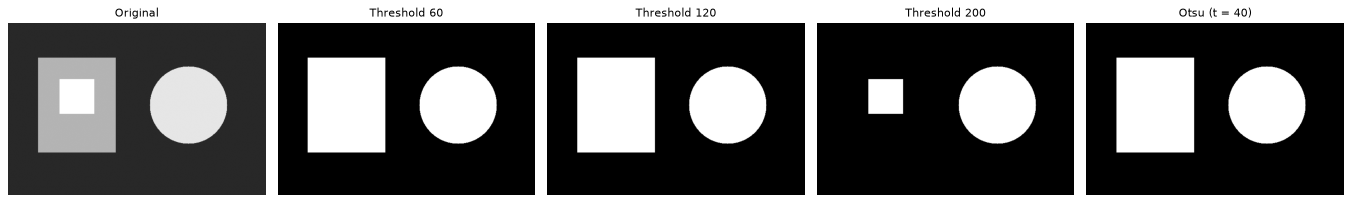

threshold  60: IoU = 1.000   objects kept: rectangle (180), circle (230), small square (255)
threshold 120: IoU = 1.000   objects kept: rectangle (180), circle (230), small square (255)
threshold 200: IoU = 0.489   objects kept: circle (230), small square (255)
Otsu  (40): IoU = 1.000   objects kept: rectangle (180), circle (230), small square (255)


In [4]:
objects = img > 40          # ground truth: everything that is not background

def iou(pred, truth):
    pred = pred > 0
    return np.sum(pred & truth) / np.sum(pred | truth)

def describe(binary):
    kept = [name for name, (x, y) in {"rectangle (180)": (90, 280), "circle (230)": (420, 260),
                                      "small square (255)": (160, 170)}.items() if binary[y, x] > 0]
    return ", ".join(kept) if kept else "nothing"

otsu_t, otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
manual = {t: cv2.threshold(img, t, 255, cv2.THRESH_BINARY)[1] for t in (60, 120, 200)}

show([img] + list(manual.values()) + [otsu],
     ["Original"] + [f"Threshold {t}" for t in manual] + [f"Otsu (t = {otsu_t:.0f})"], cols=5)

for t, b in manual.items():
    print(f"threshold {t:>3}: IoU = {iou(b, objects):.3f}   objects kept: {describe(b)}")
print(f"Otsu  ({otsu_t:.0f}): IoU = {iou(otsu, objects):.3f}   objects kept: {describe(otsu)}")

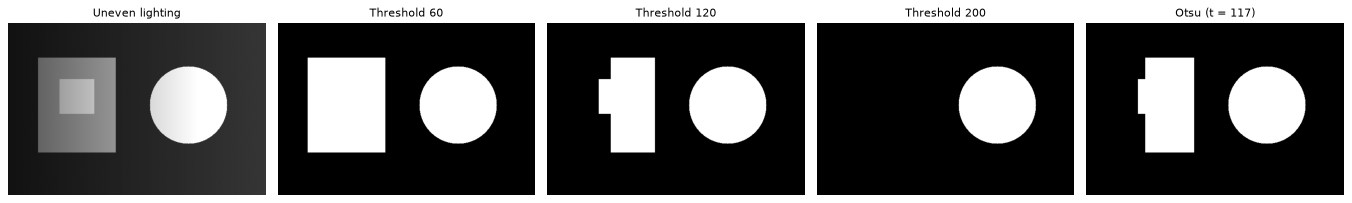

uneven, threshold  60: IoU = 1.000   objects kept: rectangle (180), circle (230), small square (255)
uneven, threshold 120: IoU = 0.771   objects kept: circle (230), small square (255)
uneven, threshold 200: IoU = 0.389   objects kept: circle (230)
uneven, Otsu  (117): IoU = 0.795   objects kept: circle (230), small square (255)


In [5]:
# When does a manual threshold fail? Same image under uneven lighting (dark on the left, bright on the right)
light = np.tile(np.linspace(0.45, 1.35, img.shape[1]), (img.shape[0], 1))
uneven = np.clip(img * light, 0, 255).astype(np.uint8)

manual_uneven = {t: cv2.threshold(uneven, t, 255, cv2.THRESH_BINARY)[1] for t in (60, 120, 200)}
ot_u, otsu_uneven = cv2.threshold(uneven, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

show([uneven] + list(manual_uneven.values()) + [otsu_uneven],
     ["Uneven lighting"] + [f"Threshold {t}" for t in manual_uneven] + [f"Otsu (t = {ot_u:.0f})"], cols=5)
for t, b in manual_uneven.items():
    print(f"uneven, threshold {t:>3}: IoU = {iou(b, objects):.3f}   objects kept: {describe(b)}")
print(f"uneven, Otsu  ({ot_u:.0f}): IoU = {iou(otsu_uneven, objects):.3f}   objects kept: {describe(otsu_uneven)}")

- On the clean image, 60 and 120 both separate all three objects (IoU = 1.0). **200 fails**: the rectangle has intensity 180, which is below the threshold, so it disappears (IoU 0.49).
- Otsu picks **t = 40** automatically and finds all three objects.
- Under **uneven lighting**, the left side is darker. Threshold 120 now loses the rectangle, 200 keeps only the circle, and even Otsu (117) loses the rectangle, because one global value cannot fit both the dark and the bright side.

**When does a manual threshold fail?**
1. When the threshold sits above the intensity of an object you need, or below the background.
2. When the lighting changes across the image, because the same object has different intensities in different places. Adaptive thresholding is the fix here.
3. When noise pushes pixels across the threshold.
4. When you reuse a value tuned for one image on another image. It has to be tuned again for every image.

### Task 4 — Morphology (Solution)

original         specks left:  50 | hole filled: False | gap closed: False | object area: 66563
opening  3x3    specks left:  51 | hole filled: False | gap closed: False | object area: 66563
closing  3x3    specks left:  48 | hole filled: False | gap closed: False | object area: 66563
opening  7x7    specks left:   0 | hole filled: False | gap closed: False | object area: 66563
closing  7x7    specks left:  44 | hole filled: False | gap closed: False | object area: 66563
opening 11x11   specks left:   0 | hole filled: False | gap closed: False | object area: 66563
closing 11x11   specks left:  42 | hole filled: False | gap closed: True  | object area: 68372
closing 15x15   specks left:  41 | hole filled: True  | gap closed: True  | object area: 68541  <- extra, not asked


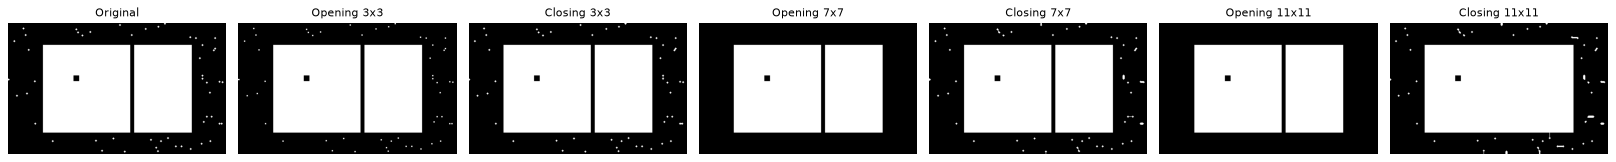

In [6]:
# Same mask as the section: white rectangle + background specks + a 13x13 hole + a 9 px wide gap
mask = np.zeros((300, 500), dtype=np.uint8)
cv2.rectangle(mask, (80, 50), (420, 250), 255, -1)
np.random.seed(42)
for _ in range(120):
    x, y = np.random.randint(0, 500), np.random.randint(0, 300)
    if x < 70 or x > 430 or y < 40 or y > 260:
        cv2.circle(mask, (x, y), 2, 255, -1)
cv2.rectangle(mask, (150, 120), (162, 132), 0, -1)   # hole
cv2.rectangle(mask, (280, 50), (288, 250), 0, -1)    # gap

def report(m):
    outside = m.copy()
    outside[45:256, 75:426] = 0                        # ignore the big object, count only specks
    specks = cv2.connectedComponents(outside)[0] - 1
    return (f"specks left: {specks:>3} | hole filled: {m[126, 156] == 255!s:<5} | "
            f"gap closed: {m[150, 284] == 255!s:<5} | object area: {np.count_nonzero(m[50:251, 80:421])}")

images, titles = [mask], ["Original"]
print(f"{'original':<16}", report(mask))
for k in (3, 7, 11):
    kernel = np.ones((k, k), np.uint8)
    opened = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    closed = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    images += [opened, closed]
    titles += [f"Opening {k}x{k}", f"Closing {k}x{k}"]
    print(f"opening {k:>2}x{k:<2}  ", report(opened))
    print(f"closing {k:>2}x{k:<2}  ", report(closed))

# extra: the hole is 13x13, so it needs a kernel bigger than that
closed15 = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
print(f"closing 15x15  ", report(closed15), " <- extra, not asked")

show(images, titles, cols=7, size=2.9)

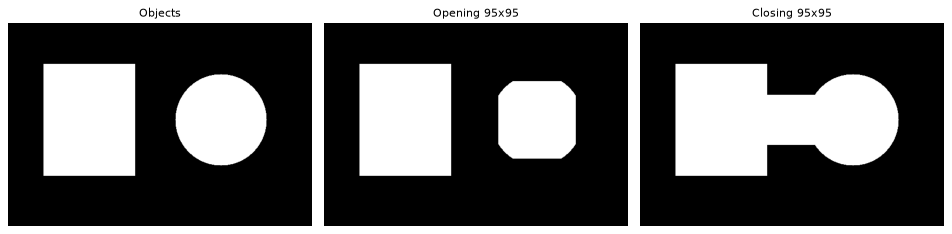

objects: 2 | after opening 95x95: 2 | after closing 95x95: 1
circle area kept by opening: 86%


In [7]:
# Kernel too large: binary version of the test image (rectangle + circle, 80 px apart)
shapes = cv2.threshold(img, 100, 255, cv2.THRESH_BINARY)[1]
big = np.ones((95, 95), np.uint8)
open_big = cv2.morphologyEx(shapes, cv2.MORPH_OPEN, big)
close_big = cv2.morphologyEx(shapes, cv2.MORPH_CLOSE, big)

n_objects = lambda m: cv2.connectedComponents(m)[0] - 1
show([shapes, open_big, close_big],
     ["Objects", "Opening 95x95", "Closing 95x95"], size=4)
print("objects:", n_objects(shapes), "| after opening 95x95:", n_objects(open_big),
      "| after closing 95x95:", n_objects(close_big))
print(f"circle area kept by opening: {np.count_nonzero(open_big[:, 330:]) / np.count_nonzero(shapes[:, 330:]):.0%}")

| Kernel | Opening | Closing |
|---|---|---|
| 3×3 | Does nothing useful. The specks (5 px dots) are bigger than the kernel, so they survive. | Does not fill the 13 px hole or the 9 px gap. |
| 7×7 | **Removes all the specks** and keeps the rectangle unchanged. | Still too small for the hole and the gap. |
| 11×11 | Removes all the specks. | **Closes the 9 px gap**, but the 13 px hole stays (it needs about 15×15). |

Rule: **opening removes white things smaller than the kernel; closing fills black holes and gaps smaller than the kernel.**

**What happens when the kernel becomes too large?** It starts to damage the real objects:
- **Opening** with 95×95 cuts the round parts of the circle (only 86% of its area is left) and would delete any object thinner than the kernel.
- **Closing** with 95×95 joins the rectangle and the circle into **one object** (2 → 1), because the 80 px gap between them is smaller than the kernel.

So the kernel should be just bigger than the noise or gap you want to fix, and smaller than the objects and the spaces between them.

### Task 5 — Canny (Solution)

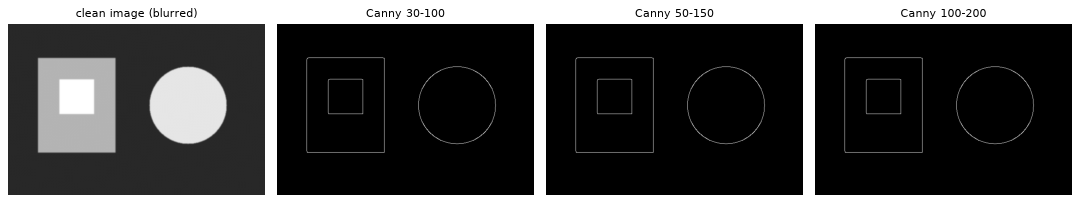

clean image (blurred)        Canny  30-100: edge pixels =   1744, unwanted =      0
clean image (blurred)        Canny  50-150: edge pixels =   1744, unwanted =      0
clean image (blurred)        Canny 100-200: edge pixels =   1744, unwanted =      0


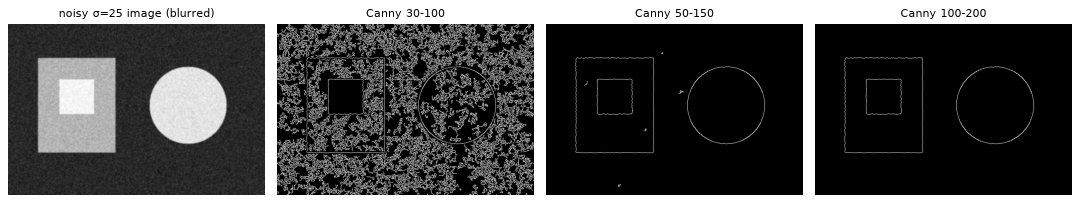

noisy σ=25 image (blurred)   Canny  30-100: edge pixels =  53784, unwanted =  51969
noisy σ=25 image (blurred)   Canny  50-150: edge pixels =   1871, unwanted =     85
noisy σ=25 image (blurred)   Canny 100-200: edge pixels =   1786, unwanted =      0


In [8]:
# True boundaries of the clean image (allow 2 px tolerance)
true_edges = cv2.dilate(cv2.Canny(img, 50, 150), np.ones((5, 5), np.uint8))

settings = [(30, 100), (50, 150), (100, 200)]
clean_blur = cv2.GaussianBlur(img, (5, 5), 0)
noisy_blur = cv2.GaussianBlur(g25, (5, 5), 0)

for source, label in [(clean_blur, "clean image (blurred)"), (noisy_blur, "noisy σ=25 image (blurred)")]:
    edges = [cv2.Canny(source, lo, hi) for lo, hi in settings]
    show([source] + edges, [label] + [f"Canny {lo}-{hi}" for lo, hi in settings], cols=4)
    for (lo, hi), e in zip(settings, edges):
        total = np.count_nonzero(e)
        unwanted = np.count_nonzero((e > 0) & (true_edges == 0))
        print(f"{label:<28} Canny {lo:>3}-{hi:<3}: edge pixels = {total:>6}, unwanted = {unwanted:>6}")

- **On the clean image**, all three settings give the same 1,744 edge pixels, because every edge is a strong step that passes even the high threshold.
- **On the noisy image**, the difference is huge:
  - **(30, 100)** detects the most edges (53,784 pixels), but **51,969 of them are unwanted** noise edges.
  - **(50, 150)** gives 1,871 edge pixels, of which only 85 are wrong.
  - **(100, 200)** gives 1,786 edge pixels with **no** wrong edges.

**Answer:** low thresholds detect more edges but also produce the most unwanted edges. High thresholds keep only strong edges, which is cleaner but can miss weak, real edges in real photos. Blurring first and choosing a ratio of about 1:2 or 1:3 between the two thresholds is the usual balance.

### Task 6 — My own pipeline (Solution)

**Read → Grayscale → Noise → Filter → Threshold → Morphology → Canny** on OpenCV's `fruits.jpg`.

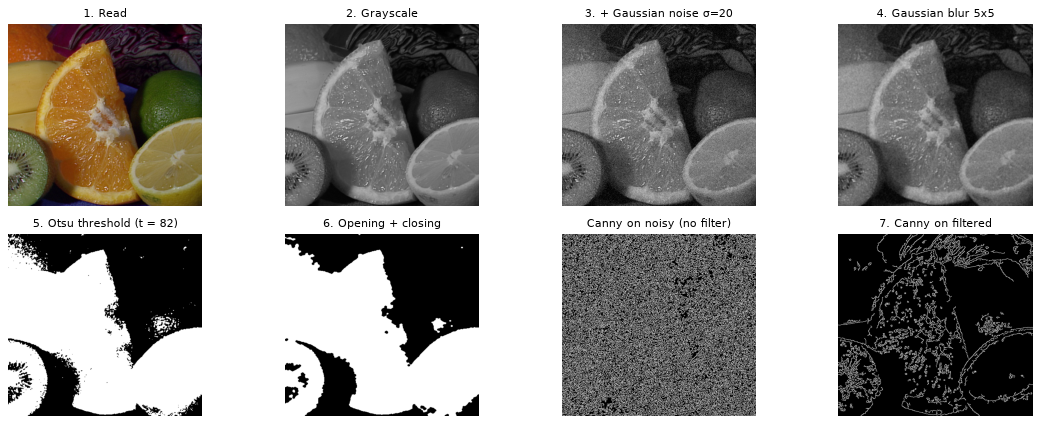

edge pixels without filtering: 88538
edge pixels after filtering:   19254
white regions before / after morphology: 163 / 9


In [9]:
# 1. Read: a real photo (downloaded once from the OpenCV samples)
PHOTO = "fruits.jpg"
if not os.path.exists(PHOTO):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/fruits.jpg", PHOTO)
photo = cv2.imread(PHOTO)

# 2. Grayscale: thresholding, morphology and Canny all work on one intensity channel
gray = cv2.cvtColor(photo, cv2.COLOR_BGR2GRAY)

# 3. Noise: simulate a low-light camera (Gaussian noise) to see how each step copes with it
np.random.seed(0)
noisy = add_gaussian_noise(gray, sigma=20)

# 4. Filter: the noise is Gaussian, so a Gaussian blur fits it; 5x5 removes most grain
#    without melting the fruit outlines (11x11 would blur them a lot, see Task 2)
smooth = cv2.GaussianBlur(noisy, (5, 5), 0)

# 5. Threshold: lighting is fairly even and the histogram has a bright group (fruit) and a
#    dark group (cabbage / shadows), so Otsu can pick the global threshold automatically
t, binary = cv2.threshold(smooth, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 6. Morphology: opening (5x5) removes small white specks left by the threshold,
#    closing (7x7) fills small dark holes such as seeds and highlights inside the fruit
k_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
k_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
clean_mask = cv2.morphologyEx(binary, cv2.MORPH_OPEN, k_open)
clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, k_close)

# 7. Canny on the smoothed image: blurring first stops the noise from creating fake edges
edges_noisy = cv2.Canny(noisy, 50, 150)
edges = cv2.Canny(smooth, 50, 150)

show([photo, gray, noisy, smooth, binary, clean_mask, edges_noisy, edges],
     ["1. Read", "2. Grayscale", "3. + Gaussian noise σ=20", "4. Gaussian blur 5x5",
      f"5. Otsu threshold (t = {t:.0f})", "6. Opening + closing", "Canny on noisy (no filter)",
      "7. Canny on filtered"], cols=4, size=3.6)

print("edge pixels without filtering:", np.count_nonzero(edges_noisy))
print("edge pixels after filtering:  ", np.count_nonzero(edges))
print("white regions before / after morphology:",
      cv2.connectedComponents(binary)[0] - 1, "/", cv2.connectedComponents(clean_mask)[0] - 1)

The reason for each step is in the comments above. The numbers show that the steps help:
- **Filtering before Canny** cut the edge pixels from 88,538 (mostly noise) to 19,254, so the fruit outlines are visible again.
- **Morphology** reduced the white regions after thresholding from 163 small pieces to 9 clean regions.

### Final Challenge — Document Cleanup (Solution)

A synthetic "photographed document" is used so the result can be checked against the real text: it has **uneven lighting** (a shadow on the left), **noise**, **dark text** and **small gaps in the letters**.

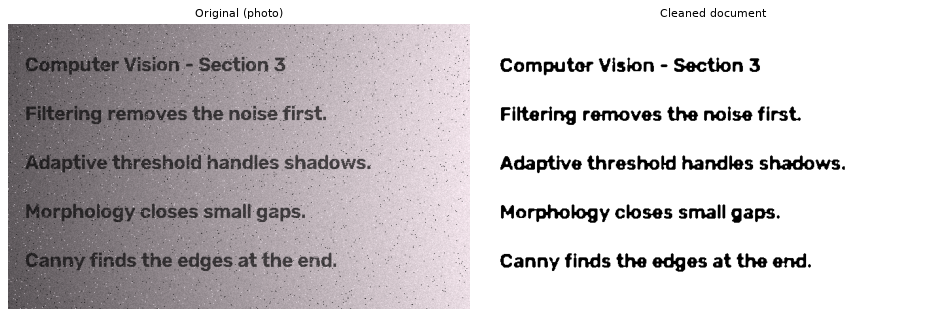

In [10]:
def make_document(seed=3):
    rng = np.random.default_rng(seed)
    h, w = 420, 680
    text = np.zeros((h, w), np.uint8)
    lines = ["Computer Vision - Section 3",
             "Filtering removes the noise first.",
             "Adaptive threshold handles shadows.",
             "Morphology closes small gaps.",
             "Canny finds the edges at the end."]
    for i, line in enumerate(lines):
        cv2.putText(text, line, (25, 70 + i * 72), cv2.FONT_HERSHEY_SIMPLEX, 1.0, 255, 2, cv2.LINE_AA)
    truth = text > 127                       # the real text, used only to score the results

    broken = truth.copy()                    # small gaps in the letters
    for _ in range(260):
        y, x = rng.integers(0, h), rng.integers(0, w - 6)
        broken[y, x:x + 6] = False

    # paper brightness: dark shadow on the left, brighter on the right, slight vignette
    yy, xx = np.mgrid[0:h, 0:w]
    paper = 95 + 140 * (xx / w) - 25 * ((yy - h / 2) / h) ** 2
    page = paper * np.where(broken, 0.35, 1.0)
    page = page + rng.normal(0, 9, page.shape)                       # sensor noise
    page = np.clip(page, 0, 255).astype(np.uint8)
    specks = rng.random(page.shape)
    page[specks < 0.006] = 0
    page[specks > 0.994] = 255                                        # salt & pepper dust
    color = cv2.merge([page, np.clip(page * 0.97, 0, 255).astype(np.uint8),
                       np.clip(page * 1.03, 0, 255).astype(np.uint8)])  # slightly warm "photo"
    return color, truth

document_image, truth = make_document()

# Step 0: grayscale
gray_doc = cv2.cvtColor(document_image, cv2.COLOR_BGR2GRAY)

# Step 1: filtering - median 3 removes the salt & pepper dust and keeps the letter edges sharp
filtered = cv2.medianBlur(gray_doc, 3)

# Step 2: adaptive threshold - each pixel is compared with its own 31x31 neighbourhood,
# so the dark shadow on the left does not matter. INV makes the text white (foreground).
text_mask = cv2.adaptiveThreshold(filtered, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                  cv2.THRESH_BINARY_INV, 31, 15)

# Step 3: morphology - opening removes leftover specks, closing fills the small gaps in the letters
text_mask = cv2.morphologyEx(text_mask, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))
text_mask = cv2.morphologyEx(text_mask, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
clean_doc = cv2.bitwise_not(text_mask)       # back to black text on white paper

show([document_image, clean_doc], ["Original (photo)", "Cleaned document"], size=6)

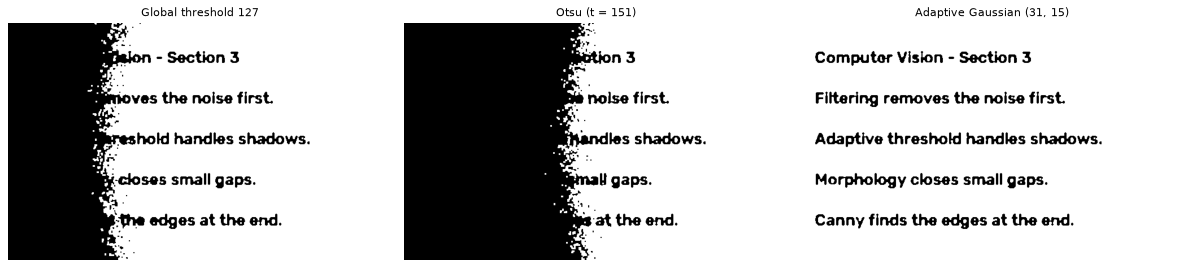

method                     F1   text found   paper marked as text
Global 127              0.308        87.1%                 26.86%
Otsu (151)              0.230        93.0%                 43.69%
Adaptive                0.761        77.0%                  1.81%


In [11]:
# Extension: global vs Otsu vs adaptive (same filtering and morphology for all three)
def finish(text_white):
    m = cv2.morphologyEx(text_white, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))
    return cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))

global_t = finish(cv2.threshold(filtered, 127, 255, cv2.THRESH_BINARY_INV)[1])
otsu_value, otsu_raw = cv2.threshold(filtered, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
otsu_t = finish(otsu_raw)
adaptive_t = text_mask

def score(pred_white):
    pred = pred_white > 0
    tp = np.sum(pred & truth)
    precision = tp / max(np.sum(pred), 1)
    recall = tp / np.sum(truth)
    f1 = 2 * precision * recall / max(precision + recall, 1e-9)
    wrong_paper = np.mean(pred[~truth]) * 100
    return f1, recall, wrong_paper

show([cv2.bitwise_not(global_t), cv2.bitwise_not(otsu_t), cv2.bitwise_not(adaptive_t)],
     ["Global threshold 127", f"Otsu (t = {otsu_value:.0f})", "Adaptive Gaussian (31, 15)"], cols=3, size=5)

print(f"{'method':<22}{'F1':>7}{'text found':>13}{'paper marked as text':>23}")
for name, m in [("Global 127", global_t), (f"Otsu ({otsu_value:.0f})", otsu_t), ("Adaptive", adaptive_t)]:
    f1, rec, wrong = score(m)
    print(f"{name:<22}{f1:>7.3f}{rec * 100:>12.1f}%{wrong:>22.2f}%")

**Which method works best, and why? → Adaptive.**
- **Global 127** and **Otsu (151)** use one value for the whole page. The paper on the shadowed left side is darker than the threshold, so it is classified as text and the whole left part turns black: about 27% and 44% of the paper is wrong, and the F1 score is only 0.31 and 0.23.
- **Adaptive (Gaussian, 31×31 block, C = 15)** compares each pixel with its own neighbourhood. A letter is always darker than the paper right around it, even inside the shadow, so the text comes out on both sides and only **1.8%** of the paper is wrong, with **F1 = 0.76**.
- Before the threshold, the **median 3** filter removes the dust. After it, **opening** removes the leftover dots and **closing** fills the small gaps inside the letters.

Otsu is not "wrong": it is the best global value for this histogram. But no single global value can work when the lighting changes across the page.